In [1]:
import duckdb
import matplotlib.pyplot as plt

file = "'../data/process_data.json'"

exploded_events = duckdb.sql(f"""
        WITH unnested AS(
        SELECT Time as processing_time,
        unnest(ProcessData::JSON[]) as event
        FROM {file}
        )

        SELECT processing_time,
        event->>'$.Name' as name,
        event->>'$.Value' as value,
        event->>'$.Type' as type,
        event->>'$.Time' as event_time,
        event->>'$.Unit' as unit,
        FROM unnested
        """)

df = duckdb.sql("""
        WITH pivoted AS(
        PIVOT exploded_events
        ON name
        USING FIRST(value)
        GROUP BY processing_time
        ORDER BY processing_time
        )
        SELECT CAST(processing_time AS TIMESTAMP_MS) as time,
        CAST("fDrahtlaenge1 (Drehgeber)" AS DOUBLE) as drahtlaenge,
        CAST("fDurchmesser1 (Haerten)" AS DOUBLE) as durchmesser,
        FROM pivoted
        """).df()

Text(0, 0.5, 'Drahtdurchmesser [mm]')

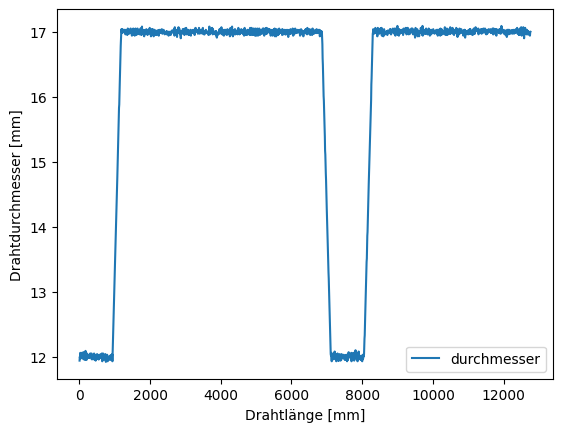

In [2]:
# Visualisierung des Durchmessers
df[df["time"] <= "2026-01-01 06:03:00.000"].plot(kind="line", x="drahtlaenge", y="durchmesser")
plt.xlabel("Drahtlänge [mm]")
plt.ylabel("Drahtdurchmesser [mm]")

In [3]:
# Rollender Durchschnitt um kurze Ausreißer zu glätten
df["durchmesser_rolling"] = df["durchmesser"].rolling(window=10, min_periods=1).median()

Text(0, 0.5, 'durchmesser_smooth [mm]')

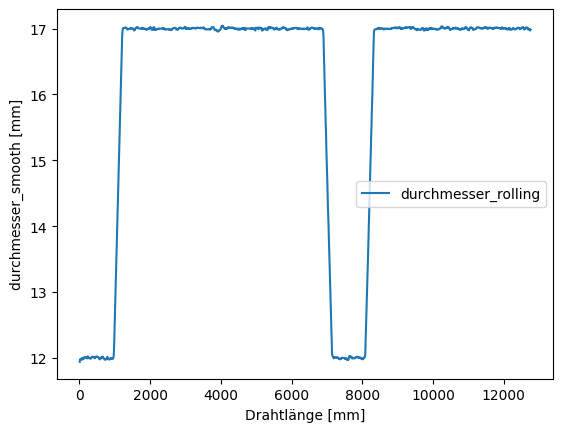

In [4]:
# Prüfen ob die Glättung passt
df[df["time"] <= "2026-01-01 06:03:00.000"].plot(
    kind="line", x="drahtlaenge", y="durchmesser_rolling"
)
plt.xlabel("Drahtlänge [mm]")
plt.ylabel("durchmesser_smooth [mm]")

<Axes: ylabel='Frequency'>

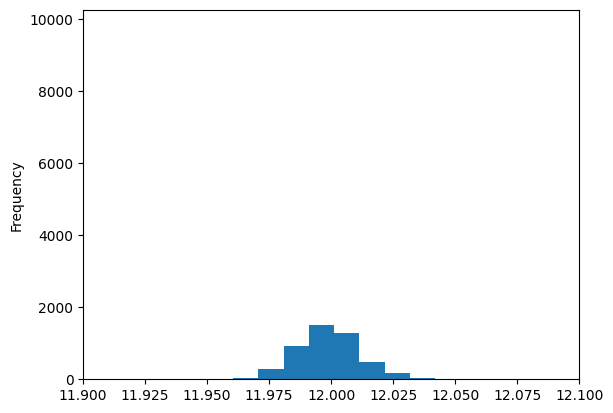

In [5]:
# Prüfung der Varianz im niedrigen Abschnitt um Plateau Toleranz festzulegen
df["durchmesser_rolling"].plot(kind="hist", bins=500, xlim=(11.9, 12.1))

<Axes: ylabel='Frequency'>

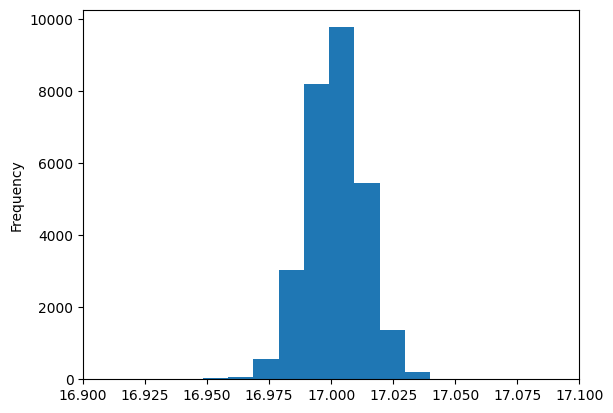

In [6]:
# Analog die Prüfung des hohen Plataus
df["durchmesser_rolling"].plot(kind="hist", bins=500, xlim=(16.9, 17.1))

In [7]:
# Zuordnung jeder Zeile zu einem Abschnitt (L1-L4)
def get_abschnitt(window, low=12.0, high=17.0, tol=0.3):

    # 0 = L1 (Hoch-Platau)
    # 1 = L2 (Tief-Plateau)
    # 2 = L3 (steigend)
    # 3 = L4 (fallend)
    # 4 = unbekannt

    window = list(window)
    latest = window[-1]

    # Plateau-Erkennung
    if abs(latest - high) <= tol:
        return 0  # hoch
    if abs(latest - low) <= tol:
        return 1  # niedrig

    # Jetzt liegt latest zwischen den Plateaus (Übergang)
    if low < latest < high:
        # Trend: Differenz zwischen letztem und erstem Wert im Fenster
        trend = window[-1] - window[0]
        if trend > 0.1:  # positive Steigung
            return 2
        elif trend < -0.1:  # negative Steigung
            return 3
        else:
            return 4  # Trend ist flach obwohl kein Plateau
    else:
        return 4


def translate_abschnitt(i):

    if i is None:
        return "NaN"

    i = int(i)
    profiles = ["hoch", "niedrig", "steigend", "fallend", "unbekannt"]
    return profiles[i]


df["abschnitt_idx"] = (
    df["durchmesser_rolling"].rolling(window=10, min_periods=1).apply(get_abschnitt)
)
df["abschnitt"] = df["abschnitt_idx"].apply(translate_abschnitt)
df.drop(columns=["abschnitt_idx"], inplace=True)

In [8]:
# prüfen wo es unbekannte Abschnitte gibt
df[df["abschnitt"] == "unbekannt"]

,time,drahtlaenge,durchmesser,durchmesser_rolling,abschnitt


In [9]:
# Filtern der Unbekannten Abschnitte, da diese aufgrund des abgeschnittenen Datensatzes auftreten
df = df[df["abschnitt"] != "unbekannt"]

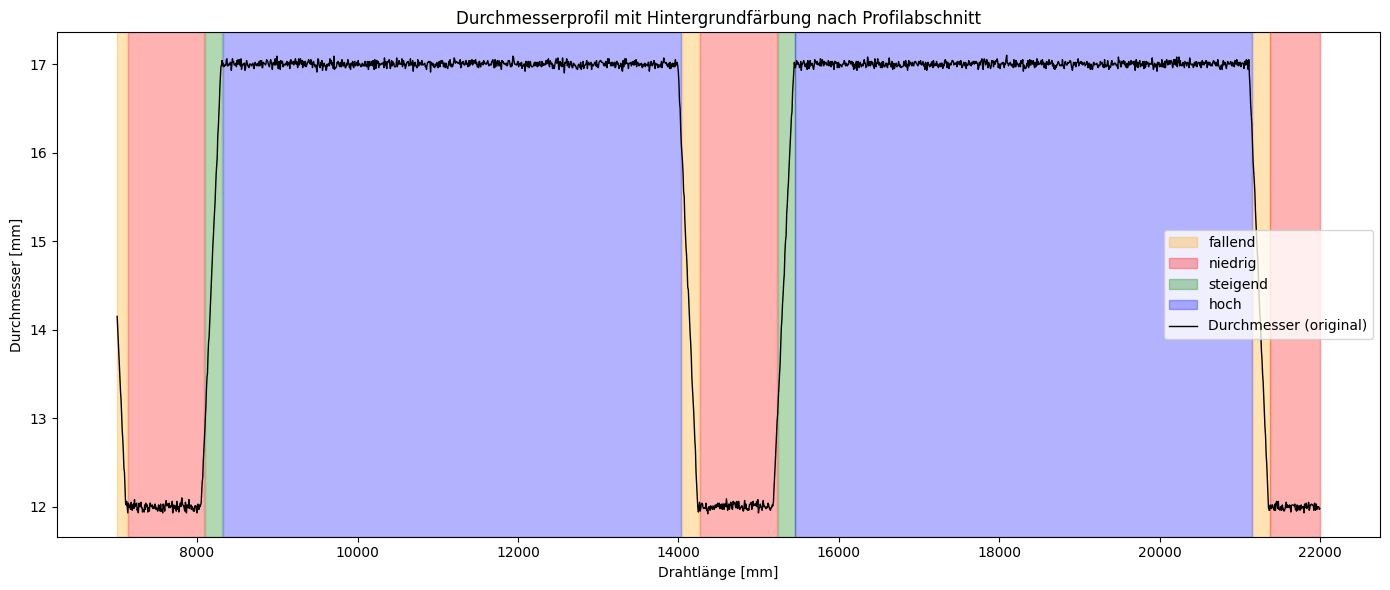

In [10]:
# Prüfen ob die Abschnitte korrekt klassifiziert werden
# Ausschnitt: die ersten beiden vollständigen Profile
df_filtered = df[(df["drahtlaenge"] >= 7000) & (df["drahtlaenge"] <= 22000)]
df_filtered = df_filtered.sort_values("drahtlaenge").reset_index(drop=True)

# Mapping von Profilbezeichnung zu Farbe
color_map = {"hoch": "blue", "niedrig": "red", "steigend": "green", "fallend": "orange"}

# Wechselpunkte der Profile finden (jede Gruppe gleichen Profils)
df_filtered["wechsel_id"] = df_filtered["abschnitt"].ne(df_filtered["abschnitt"].shift()).cumsum()

# Plot erstellen
fig, ax = plt.subplots(figsize=(14, 6))

# Hintergrund farbig markieren
for _, group in df_filtered.groupby("wechsel_id"):
    start = group["drahtlaenge"].iloc[0]
    end = group["drahtlaenge"].iloc[-1]
    profil = group["abschnitt"].iloc[0]
    farbe = color_map.get(profil, "gray")
    ax.axvspan(start, end, alpha=0.3, color=farbe, label=profil)

# Durchmesser‑Linie plotten (hier mit geglätteten Werten, falls gewünscht)
ax.plot(
    df_filtered["drahtlaenge"],
    df_filtered["durchmesser"],
    color="black",
    linewidth=1,
    label="Durchmesser (original)",
)

# Achsenbeschriftung und Titel
ax.set_xlabel("Drahtlänge [mm]")
ax.set_ylabel("Durchmesser [mm]")
ax.set_title("Durchmesserprofil mit Hintergrundfärbung nach Profilabschnitt")

# Legende (nur einmal pro Farbe)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles, strict=True))  # entfernt Duplikate
ax.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

In [11]:
# Erkennung jedes Profils anhand der Abfolge der Abschnitte
df["profilbeginn"] = (df["abschnitt"] == "niedrig") & (df["abschnitt"].shift(1) != "niedrig")
df["profile_id"] = df["profilbeginn"].cumsum()

In [12]:
# Unvollständige Profile rausfiltern (erstes und letztes Profil sind am Datenrand abgeschnitten)
erstes = df["profile_id"].min()
letztes = df["profile_id"].max()
df = df[(df["profile_id"] != erstes) & (df["profile_id"] != letztes)]

In [13]:
# Berechnung der Länge jedes Abschnittes
abschnitte = (
    df.groupby(["profile_id", "abschnitt"])
    .agg(start=("drahtlaenge", "min"), ende=("drahtlaenge", "max"))
    .reset_index()
)
abschnitte["länge"] = abschnitte["ende"] - abschnitte["start"]

# Berechnung der durchschnittlichen Länge je Abschnitt
abschnitt_means = abschnitte.groupby("abschnitt").agg(durchschnitt_länge=("länge", "mean"))
abschnitt_means

,durchschnitt_länge
abschnitt,
fallend,208.807588
hoch,5700.272382
niedrig,954.686765
steigend,208.996588


In [14]:
# Kennzeichnen von Abschnitten, die nicht in Ordnung sind (30mm Abweichung vom Mittelwert)
def check_abschnitt(row):
    abschnitt = row["abschnitt"]
    länge = row["länge"]

    mean = abschnitt_means.loc[abschnitt, "durchschnitt_länge"]

    return abs(länge - mean) <= 30


abschnitte["i.O."] = abschnitte.apply(check_abschnitt, axis=1)

In [15]:
# Aggregation auf Profile
profiles = (
    abschnitte.groupby("profile_id")
    .agg({"i.O.": "all", "start": "min", "ende": "max", "länge": "sum"})
    .reset_index()
)
profiles

,profile_id,i.O.,start,ende,länge
0,2,True,7137.099,14256.111,7098.437
1,3,True,14263.424,21369.321,7083.590
2,4,True,21376.632,28493.177,7095.911
3,5,False,28499.536,35523.193,7003.131
4,6,True,35530.109,42641.801,7090.917
5,7,True,42648.678,49750.231,7081.488
6,8,True,49757.373,56826.670,7047.921
7,9,True,56833.267,63940.078,7086.796
8,10,True,63947.398,71014.350,7046.070
9,11,True,71021.809,78114.037,7069.675


In [16]:
profiles[:50]

,profile_id,i.O.,start,ende,länge
0,2,True,7137.099,14256.111,7098.437
1,3,True,14263.424,21369.321,7083.590
2,4,True,21376.632,28493.177,7095.911
3,5,False,28499.536,35523.193,7003.131
4,6,True,35530.109,42641.801,7090.917
5,7,True,42648.678,49750.231,7081.488
6,8,True,49757.373,56826.670,7047.921
7,9,True,56833.267,63940.078,7086.796
8,10,True,63947.398,71014.350,7046.070
9,11,True,71021.809,78114.037,7069.675


**Soll-Längen für Job 3**

Der Flink-Job misst die Abschnittslängen anders als die Analyse oben: Er hält bei jedem Abschnittswechsel die Drahtlänge fest. Die Bänder von ±0,3 mm um 12 und 17 mm zählen dabei Anfang und Ende jeder Rampe zum Plateau, deshalb fallen die Rampen kürzer und die Plateaus länger aus als die Konstruktionsmaße des Generators (940 / 245 / 5680 / 245 mm).

Die Soll-Längen in `src/transform/profile_classification_logic.py` sind deshalb mit der Logik des Jobs selbst gemessen. Der Median statt des Mittelwerts, damit die n.i.O.-Profile die Sollwerte nicht verschieben.

In [17]:
import sys

import pandas as pd

sys.path.append("../src/transform")
from profile_classification_logic import TARGET_LENGTHS, new_state, update  # noqa: E402

# Alle Messwerte neu laden: df ist oben schon gefiltert
raw = duckdb.sql(f"""
        SELECT
            CAST(list_filter(ProcessData, x -> x.Name = 'fDrahtlaenge1 (Drehgeber)')[1].Value AS DOUBLE) AS drahtlaenge,
            CAST(list_filter(ProcessData, x -> x.Name = 'fDurchmesser1 (Haerten)')[1].Value AS DOUBLE) AS durchmesser
        FROM {file}
        ORDER BY Time
        """).df()

state = new_state()
job_profiles = []
for drahtlaenge, durchmesser in raw.itertuples(index=False):
    state, profile = update(state, drahtlaenge, durchmesser)
    if profile is not None:
        job_profiles.append(profile)

job_profiles = pd.DataFrame(job_profiles)
gemessen = job_profiles[["L2", "L3", "L1", "L4"]].median()
gemessen.index = ["niedrig", "steigend", "hoch", "fallend"]
pd.DataFrame({"Median gemessen": gemessen.round(), "Soll im Job": pd.Series(TARGET_LENGTHS)})

,Median gemessen,Soll im Job
niedrig,952.0,952
steigend,210.0,210
hoch,5710.0,5710
fallend,209.0,209


In [18]:
# Ergebnis mit diesen Sollwerten: Anzahl i.O. und n.i.O.
job_profiles["iO"].value_counts()

iO
True     32
False     3
Name: count, dtype: int64